In [30]:
# coding=utf-8
import numpy as np
import pandas as pd
import seaborn as sns
from time import time
from operator import add 
from functools import reduce
import matplotlib.pyplot as plt
from numpy.random import uniform
from lib.bandits import Bernoulli, Gaussian
from lib.policies import p_auer, p_ape, p_unif
# this instance was chosen on purpose
means = np.array([[0.79561747, 0.08965442, 0.21217508, 0.70586195, 0.85819025,
        0.40859756, 0.85187629, 0.26564671, 0.53383054, 0.45786114],
       [0.68397918, 0.40962332, 0.51441263, 0.96336578, 0.9490486 ,
        0.04884175, 0.48071441, 0.87318481, 0.83631854, 0.66747994],
       [0.74498482, 0.93739875, 0.40593968, 0.04332119, 0.20483421,
        0.48585313, 0.48112598, 0.92750909, 0.38463631, 0.73104455],
       [0.62638832, 0.39101109, 0.53579913, 0.95666807, 0.18012455,
        0.68562863, 0.40986873, 0.61513398, 0.40567299, 0.53075932],
       [0.95920701, 0.96463939, 0.17122914, 0.36154627, 0.87221403,
        0.5284141 , 0.12388823, 0.84222524, 0.55235171, 0.965719  ],
       [0.74142809, 0.04686739, 0.29850367, 0.62044755, 0.27879997,
        0.44565204, 0.99344779, 0.43686477, 0.54659127, 0.41559037],
       [0.33184379, 0.27260587, 0.35171687, 0.04939323, 0.08526793,
        0.93581788, 0.64451766, 0.93243308, 0.20377   , 0.71414572],
       [0.04325666, 0.07968207, 0.05145856, 0.02163207, 0.16509912,
        0.06796036, 0.09336317, 0.10700092, 0.16536946, 0.32714854],
       [0.55893345, 0.82885115, 0.63973835, 0.74127859, 0.6955197 ,
        0.79306507, 0.47312767, 0.55239446, 0.20746722, 0.67216129],
       [0.19430824, 0.33757437, 0.66866928, 0.13386218, 0.59399642,
        0.0776997 , 0.33667443, 0.77578558, 0.72887183, 0.19002947],
       [0.94917574, 0.49893058, 0.05923611, 0.56557108, 0.30197238,
        0.60146629, 0.68608079, 0.56349484, 0.16967495, 0.37826134],
       [0.55682717, 0.57309861, 0.98388775, 0.07924336, 0.06012158,
        0.21823514, 0.61801114, 0.90617615, 0.24620713, 0.06375816]])
K = 12
D = 10
inf = 1e12
bandit = Bernoulli(means)
print("[complexity]: ", bandit.H)
print("[pareto set]: ", bandit.optimal_arms)

[complexity]:  145755.42894163335
[pareto set]:  [0, 3, 4, 5, 8, 9]


In [31]:
numiter = 2000
seeds = (np.random.uniform(size=numiter)*2**31).astype(np.uint)
delta = 0.1
eps_1 = 0.
eps_2 = 0.

In [ ]:
psi_ape = p_ape(bandit)
psi_auer = p_auer(bandit)
res_psi_ape = []
pull_of_each_arm_ape = np.zeros(K, int)
pull_of_each_arm_auer = np.zeros(K, int)
for seed in seeds:
    __res = psi_ape.loop(seed, delta, eps_1, eps_2, K)
    res_psi_ape += [sum(__res[0][1])]
    pull_of_each_arm_ape += np.array(__res[0][1])
res_psi_auer = []
for seed in seeds:
     __res = psi_auer.loop(seed, delta, eps_1)
     res_psi_auer += [sum(__res[0][1])]
     pull_of_each_arm_auer += np.array(__res[0][1])
res_psi_ape = np.array(res_psi_ape, dtype=float)
res_psi_auer  = np.array(res_psi_auer, dtype=float)
print("[k=%d] [APE]:"%K, np.mean(res_psi_ape))
print("[Auer]:", np.mean(res_psi_auer))

In [35]:
pull_of_each_arm_auer/ pull_of_each_arm_ape

array([1.4102037 , 1.98219653, 1.41020015, 3.80080266, 6.91901638,
       1.33765361, 2.48554128, 1.33765312, 3.47957836, 9.46502574])

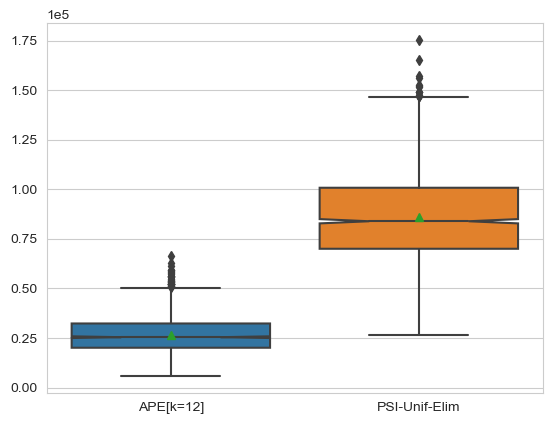

In [20]:
data = np.concatenate((res_psi_ape, res_psi_auer))
df = pd.DataFrame({"sc": data, "names": ["APE[k=%s]"%K]*seeds.size + ["PSI-Unif-Elim"]*seeds.size  })
sns.boxplot(data=df, x="names", y="sc",  orient="v", showmeans=True, showfliers=True, notch=True).set(
    xlabel=' ',
    ylabel=r'')
plt.ticklabel_format(axis="y", style="sci", scilimits=(0,0))